<a href="https://colab.research.google.com/github/rgomeza2300-cmd/M-todos-Num-ricos-I/blob/main/Diferencias_divididas.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Fórmula de diferencias divididas de Newton
## Interpolación polinomial (Algoritmo 3.2, Burden)

**Curso:** Métodos Numéricos  
**Nombre:** GOMEZ AGUIRRE ROCIO

## 1. ¿De qué trata este código?

Cuando tenemos unos cuantos puntos $(x_0, f(x_0)), (x_1, f(x_1)), \dots, (x_n, f(x_n))$, podemos encontrar un polinomio que pase exactamente por todos ellos. A esto se le llama **interpolación**.

Este código usa la **forma de Newton** del polinomio:

$$P_n(x) = a_0 + a_1(x-x_0) + a_2(x-x_0)(x-x_1) + \dots + a_n(x-x_0)\cdots(x-x_{n-1})$$

Los coeficientes $a_k$ se calculan con las **diferencias divididas**:

$$F_{i,j} = \frac{F_{i,j-1} - F_{i-1,j-1}}{x_i - x_{i-j}}, \qquad a_k = F_{k,k}$$

**Lo que hace el cuaderno:**
1. Calcula los coeficientes del polinomio (Algoritmo 3.2).
2. Con *sympy* escribe el polinomio de Newton.
3. Lo grafica.
4. Se prueba con el ejemplo 1 de la página 94 del libro de Burden.

In [20]:
# sympy sirve para escribir el polinomio y graficarlo
import sympy as sp

# matplotlib lo uso para marcar los puntos en la gráfica
import matplotlib.pyplot as plt

In [21]:
def diferencias_divididas(x, y):
    n = len(x)

    # primero hago una tabla de n x n llena de ceros
    F = []
    for i in range(n):
        fila = []
        for j in range(n):
            fila.append(0)
        F.append(fila)

    # la primera columna son los valores de f(x)
    for i in range(n):
        F[i][0] = y[i]

    # aquí se llenan las demás columnas con la fórmula
    for i in range(1, n):
        for j in range(1, i + 1):
            F[i][j] = (F[i][j-1] - F[i-1][j-1]) / (x[i] - x[i-j])

    # los coeficientes son la diagonal de la tabla
    coef = []
    for i in range(n):
        coef.append(F[i][i])

    return coef, F

## Prueba: ejemplo 1 (página 94, Burden)

Datos del libro (valores de $f(x)$ para $x = 1.0, 1.3, 1.6, 1.9, 2.2$):

In [22]:
x_datos = [1.0, 1.3, 1.6, 1.9, 2.2]
y_datos = [0.7651977, 0.6200860, 0.4554022, 0.2818186, 0.1103623]

coeficientes, tabla = diferencias_divididas(x_datos, y_datos)

# imprimo la tabla para comparar con la del libro
print("Tabla de diferencias divididas:")
for i in range(len(x_datos)):
    renglon = str(x_datos[i]) + "   "
    for j in range(i + 1):
        renglon = renglon + format(tabla[i][j], ".7f") + "   "
    print(renglon)

print()
print("Coeficientes del polinomio de Newton:")
for k in range(len(coeficientes)):
    print("a" + str(k) + " =", format(coeficientes[k], ".7f"))

Tabla de diferencias divididas:
1.0   0.7651977   
1.3   0.6200860   -0.4837057   
1.6   0.4554022   -0.5489460   -0.1087339   
1.9   0.2818186   -0.5786120   -0.0494433   0.0658784   
2.2   0.1103623   -0.5715210   0.0118183   0.0680685   0.0018251   

Coeficientes del polinomio de Newton:
a0 = 0.7651977
a1 = -0.4837057
a2 = -0.1087339
a3 = 0.0658784
a4 = 0.0018251


## Escribir el polinomio de Newton con sympy

Se va armando $P(x)$ término por término: en cada paso se multiplica el producto anterior por $(x - x_{k-1})$ y se suma el coeficiente por ese producto.

In [23]:
def polinomio_newton(coef, x_nodos):
    x = sp.Symbol('x')

    P = coef[0]       # el primer término es solo a0
    producto = 1      # aquí voy guardando (x-x0)(x-x1)...

    for k in range(1, len(coef)):
        producto = producto * (x - x_nodos[k-1])
        P = P + coef[k] * producto

    return x, P

In [24]:
x, P = polinomio_newton(coeficientes, x_datos)

print("Polinomio de Newton (forma de Newton):")
sp.pprint(P)

print()
print("Polinomio desarrollado:")
sp.pprint(sp.expand(P))

Polinomio de Newton (forma de Newton):
-0.483705666666666⋅x + 0.00182510288066044⋅(x - 1.9)⋅(x - 1.6)⋅(x - 1.3)⋅(x -  ↪

↪ 1.0) + 0.0658783950617283⋅(x - 1.6)⋅(x - 1.3)⋅(x - 1.0) - 0.108733888888889⋅ ↪

↪ (x - 1.3)⋅(x - 1.0) + 1.24890336666667

Polinomio desarrollado:
                     4                       3                      2          ↪
0.00182510288066044⋅x  + 0.0552927983538978⋅x  - 0.343046604938247⋅x  + 0.0733 ↪

↪                                   
↪ 913477366034⋅x + 0.977735055967085


## Gráfica del polinomio

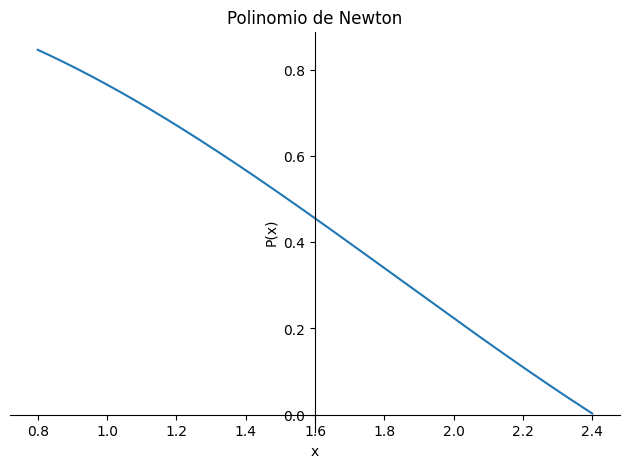

In [16]:
# gráfica con sympy
grafica = sp.plot(P, (x, 0.8, 2.4), show=False, title="Polinomio de Newton", xlabel="x", ylabel="P(x)")
grafica.show()

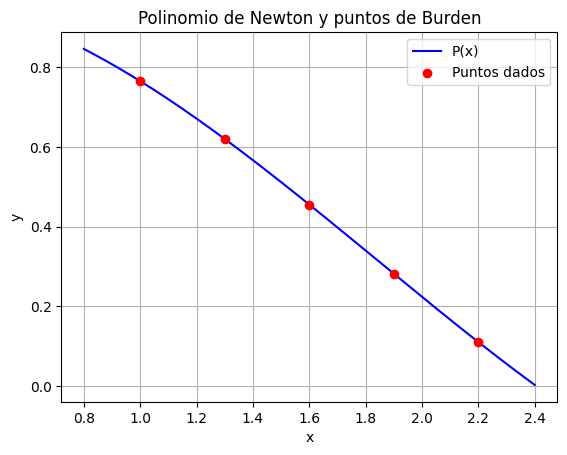

In [17]:
# la misma gráfica pero marcando los puntos originales
P_numerica = sp.lambdify(x, P)

xs = []
paso = 0.01
valor = 0.8
while valor <= 2.4:
    xs.append(valor)
    valor = valor + paso

ys = []
for v in xs:
    ys.append(P_numerica(v))

plt.plot(xs, ys, color="blue", label="P(x)")
plt.scatter(x_datos, y_datos, color="red", zorder=5, label="Puntos dados")
plt.title("Polinomio de Newton y puntos de Burden")
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.grid(True)
plt.show()

## Solución final

In [19]:
print("=" * 50)
print("SOLUCIÓN FINAL")
print("=" * 50)
print("Coeficientes de Newton:", [round(c, 7) for c in coeficientes])
print()
print("Polinomio de Newton P4(x):")
sp.pprint(P)
print("=" * 50)

SOLUCIÓN FINAL
Coeficientes de Newton: [0.7651977, -0.4837057, -0.1087339, 0.0658784, 0.0018251]

Polinomio de Newton P4(x):
-0.483705666666666⋅x + 0.00182510288066044⋅(x - 1.9)⋅(x - 1.6)⋅(x - 1.3)⋅(x -  ↪

↪ 1.0) + 0.0658783950617283⋅(x - 1.6)⋅(x - 1.3)⋅(x - 1.0) - 0.108733888888889⋅ ↪

↪ (x - 1.3)⋅(x - 1.0) + 1.24890336666667


## Conclusión

El polinomio de grado 4 pasa por los 5 puntos del ejemplo, y los coeficientes obtenidos coinciden con los de la tabla del libro de Burden. Con el Algoritmo 3.2 solo se calculan los coeficientes; con *sympy* se escribió y graficó el polinomio.